# 05 · KPI anomaly detection and investigation

**Method:** for each daily KPI, fit STL (weekly period, robust mode), then score the remainder with
a robust z-score, 0.6745·(r − median)/MAD, and flag |z| > 3.5. Counts and revenue are modelled on the
log scale. Flags on known calendar events are labelled rather than investigated.

Then the biggest unexplained anomaly is investigated: which KPI, which device, which channel, which
funnel step.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from ga4_analytics import anomaly as N
from ga4_analytics.db import Warehouse
from ga4_analytics.plots import HIGHLIGHT, NEUTRAL, PALETTE, save, use_style

use_style()
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 20)
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")
wh = Warehouse()
daily = N.load_daily(wh)
results = N.detect_all(daily)

dry run OK | local tables: ga4.main.daily_kpis, ga4.main.sessions


## Tuning: why not the STL defaults?

In [2]:
def alarm_count(seasonal, trend):
    r = N.detect_all(daily, seasonal=seasonal, trend=trend)
    a = r[r["is_anomaly"]]
    return {"seasonal": seasonal or "default (7)", "trend": trend or "default (~11)",
            "alarms": len(a), "alarms on non-event days": int(a["known_event"].isna().sum()),
            "non-event days flagged": a.loc[a["known_event"].isna(), "date"].nunique()}


pd.DataFrame([alarm_count(None, None), alarm_count(7, 29), alarm_count(15, 43),
              alarm_count(N.SEASONAL_WINDOW, N.TREND_WINDOW)])

,seasonal,trend,alarms,alarms on non-event days,non-event days flagged
0,default (7),default (~11),55,39,25
1,7,29,45,26,18
2,15,43,25,9,5
3,31,43,20,5,2


With the default windows STL follows the series so closely that it absorbs ordinary noise. Robust
fitting then leaves large residuals only on extreme days, the residual MAD shrinks, and every
z-score inflates, giving dozens of alarms on ordinary days. Stiffer windows (seasonal 31, trend
43 days) keep the baseline from chasing noise. The cost is that a genuine level shift is absorbed
more slowly; for a 3-month window of daily data that trade is worth it.

## Alarm days

In [3]:
days = N.alarm_days(results)
days

,date,kpis_flagged,kpis,max_abs_z,known_event
0,2020-12-15,4,"conversion_rate, revenue, transactions, checko...",4.538,NaN
1,2020-11-27,3,"sessions, users, revenue",8.686,Black Friday
2,2020-11-01,2,"revenue, transactions",6.647,first day of the window (partial journeys)
3,2020-11-30,2,"sessions, users",6.061,Cyber Monday
4,2020-12-23,2,"sessions, users",5.777,Christmas
5,2020-12-26,2,"sessions, users",5.153,Boxing Day
6,2020-12-25,2,"sessions, users",5.064,Christmas Day
7,2020-12-24,2,"sessions, users",4.825,Christmas Eve
8,2021-01-27,1,revenue,3.928,NaN


Seven of the nine alarm days are known calendar events (Black Friday, Cyber Monday, Christmas)
or the window's first day, and each of them fires on traffic (users and sessions). **2020-12-15 is
the only unexplained day where several KPIs fire together**, and it fires on conversion, revenue,
transactions and checkout completion, not on traffic. 2021-01-27 is a single revenue flag at
z = 3.9 near the end of the series, where LOESS fits are least stable. Watch it rather than act on it.

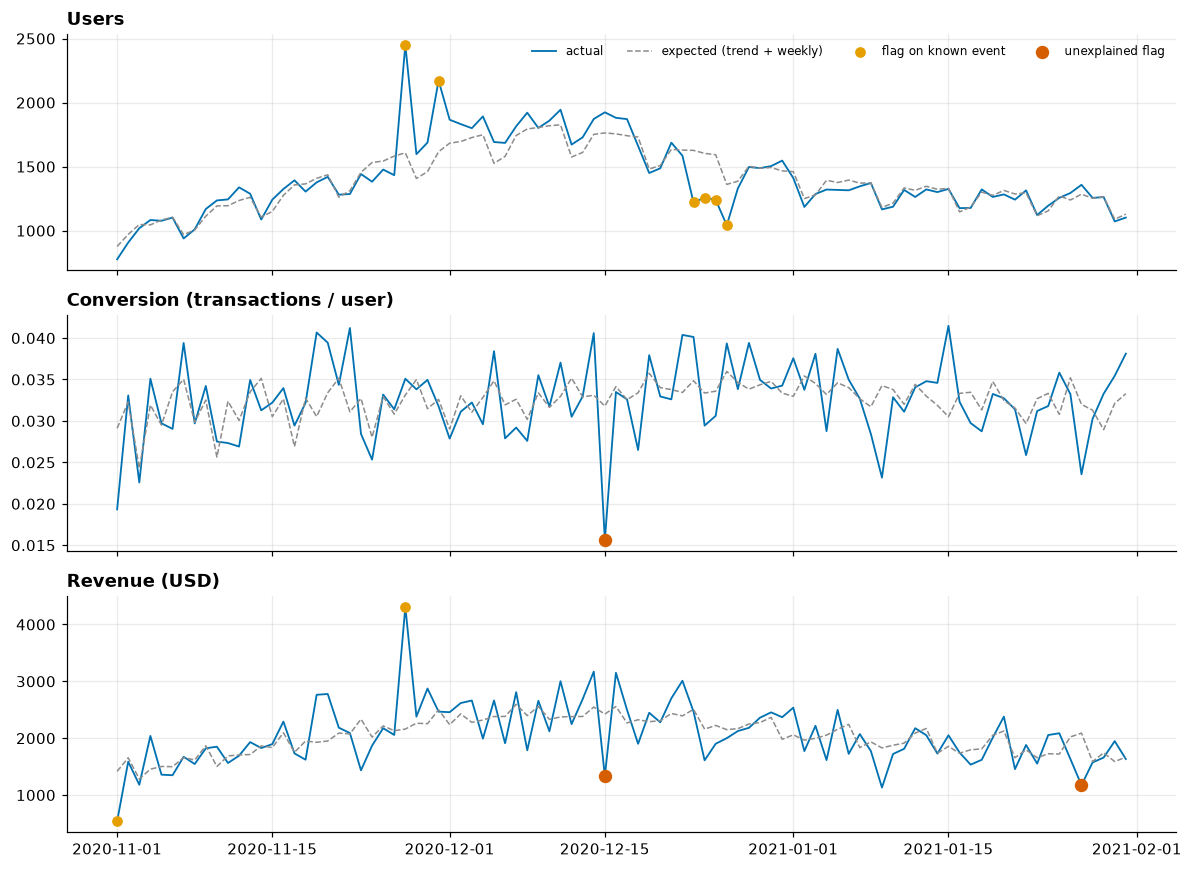

In [4]:
fig, axes = plt.subplots(3, 1, figsize=(11, 8), sharex=True)
for ax, kpi, title in zip(axes, ["users", "conversion_rate", "revenue"],
                          ["Users", "Conversion (transactions / user)", "Revenue (USD)"], strict=True):
    r = results[results["kpi"] == kpi]
    ax.plot(r["date"], r["value"], color=PALETTE[0], lw=1.2, label="actual")
    ax.plot(r["date"], r["expected"], color=NEUTRAL, lw=1, ls="--", label="expected (trend + weekly)")
    flagged = r[r["is_anomaly"]]
    known = flagged["known_event"].notna()
    ax.scatter(flagged.loc[known, "date"], flagged.loc[known, "value"], color=PALETTE[1], zorder=3,
               label="flag on known event")
    ax.scatter(flagged.loc[~known, "date"], flagged.loc[~known, "value"], color=HIGHLIGHT, zorder=4, s=60,
               label="unexplained flag")
    ax.set_title(title, loc="left")
axes[0].legend(ncols=4, loc="upper right", fontsize=8)
fig.tight_layout()
save(fig, "05_anomalies")

In [5]:
r = results[results["date"] == pd.Timestamp("2020-12-15")]
r[["kpi", "value", "expected", "pct_vs_expected", "robust_z", "is_anomaly"]]

,kpi,value,expected,pct_vs_expected,robust_z,is_anomaly
44,users,"1,924.000","1,763.029",0.091,1.644,False
136,sessions,"2,064.000","1,879.868",0.098,1.895,False
228,revenue,"1,330.460","2,423.849",-0.451,-4.088,True
320,transactions,30.000,53.549,-0.440,-4.027,True
412,conversion_rate,0.016,0.032,-0.510,-4.538,True
504,cart_rate,0.140,0.150,-0.064,-1.247,False
596,checkout_completion,0.189,0.337,-0.441,-3.915,True
688,aov,44.349,46.554,-0.047,-0.456,False


## Investigation · 2020-12-15

Baseline: the 14 days either side (28 days, the anomaly day excluded). For each segment,
*expected* = that day's sessions × the segment's baseline conversion per session.

### 1. Was it traffic or conversion?

In [6]:
counts = N.drilldown_counts(wh, "2020-12-15", baseline_days=14)
allrow = counts[counts["dimension"] == "all"].set_index("period")
pd.DataFrame({
    "anomaly day": allrow.loc["anomaly", ["sessions", "add_to_cart", "begin_checkout", "purchase"]],
    "baseline per day": allrow.loc["baseline", ["sessions", "add_to_cart", "begin_checkout", "purchase"]]
    / allrow.loc["baseline", "days"],
})

dry run OK | local tables: ga4.main.sessions


,anomaly day,baseline per day
sessions,2064,"1,766.750"
add_to_cart,289,266.750
begin_checkout,159,156.607
purchase,30,54.714


Sessions, carts and checkout starts were normal or slightly above normal. Purchases halved. People
arrived and shopped as usual; they didn't finish.

### 2. Which device?

In [7]:
dev = N.segment_shortfall(counts, "device")
dev

,sessions,baseline_sessions_per_day,actual,baseline_rate,anomaly_rate,expected,shortfall,share_of_shortfall,p_value
segment,,,,,,,,,
mobile,835,729.036,2,0.023,0.002,19.103,-17.103,0.501,0.000
desktop,1162,983.679,28,0.037,0.024,43.032,-15.032,0.440,0.021
tablet,67,54.036,0,0.030,0.000,1.993,-1.993,0.058,0.152


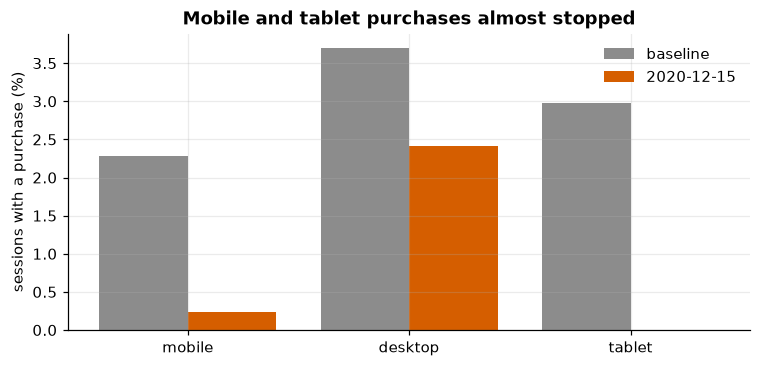

In [8]:
fig, ax = plt.subplots(figsize=(8, 3.5))
x = np.arange(len(dev))
ax.bar(x - 0.2, dev["baseline_rate"] * 100, 0.4, label="baseline", color=NEUTRAL)
ax.bar(x + 0.2, dev["anomaly_rate"] * 100, 0.4, label="2020-12-15", color=HIGHLIGHT)
ax.set_xticks(x, dev.index)
ax.set_ylabel("sessions with a purchase (%)")
ax.set_title("Mobile and tablet purchases almost stopped")
ax.legend()
save(fig, "05_incident_by_device")

Mobile made **2 purchases from 835 sessions** against about 19 expected (−90%), and tablet made 0
against 2 expected. Desktop is also below baseline (28 vs 43), which is borderline (p = 0.02).
Step 3 checks whether desktop's dip has the same shape.

### 3. Which funnel step?

In [9]:
mobile = N.step_comparison(counts, "device", "mobile")
desktop = N.step_comparison(counts, "device", "desktop")
pd.concat({"mobile": mobile, "desktop": desktop}, axis=1)

mobile                                            desktop                                      
                  anomaly_rate baseline_rate relative_change p_value anomaly_rate baseline_rate relative_change p_value
step                                                                                                                   
view_item                0.449         0.464          -0.033   0.389        0.437         0.454          -0.038   0.252
add_to_cart              0.333         0.328           0.015   0.841        0.301         0.331          -0.090   0.163
begin_checkout           0.568         0.585          -0.029   0.703        0.556         0.586          -0.052   0.449
add_shipping_info        0.761         0.741           0.027   0.709        0.682         0.747          -0.087   0.176
add_payment_info         0.611         0.692          -0.116   0.210        0.793         0.809          -0.019   0.766
purchase                 0.061         0.501          -0.879   0.000        0.609         0.695          -0.125   0.210

On mobile everything up to `add_payment_info` is normal, then **purchase given payment fell from
50% to 6%** (p < 0.001). Users entered payment details and the order did not go through.

Desktop's dip has a different shape. Every step is slightly lower and none is significant on its
own: diffuse noise, not a broken step. With three devices tested, one borderline p = 0.02 is what
chance produces about one time in eight, so desktop isn't part of the incident.

### 4. Channel? (ruling out a marketing cause)

In [10]:
N.segment_shortfall(counts, "channel")[["sessions", "actual", "expected", "shortfall", "share_of_shortfall", "p_value"]]

,sessions,actual,expected,shortfall,share_of_shortfall,p_value
segment,,,,,,
Organic Search,559,4,14.548,-10.548,0.316,0.005
Paid Search,284,3,10.140,-7.140,0.214,0.023
Direct,447,13,17.974,-4.974,0.149,0.238
Email,177,6,9.988,-3.988,0.120,0.199
Referral,163,1,3.541,-2.541,0.076,0.175
Affiliates,68,0,1.631,-1.631,0.049,0.196
Display,179,1,2.358,-1.358,0.041,0.378
Organic Social,187,2,3.149,-1.149,0.034,0.520


Every channel is below expected, and no single channel or campaign accounts for most of the
shortfall. Organic and Paid Search show the largest gaps (together about half). A marketing cause,
such as a broken campaign link or a bad promo, would concentrate in one channel and leave the
others normal. The device split explains the day far better than the channel split.

### 5. Operating system

In [11]:
N.segment_shortfall(counts, "operating_system")[["sessions", "actual", "expected", "shortfall", "p_value"]]

,sessions,actual,expected,shortfall,p_value
segment,,,,,
Windows,604,10,21.890,-11.890,0.010
iOS,486,1,10.419,-9.419,0.003
Android,362,1,9.313,-8.313,0.006
Macintosh,391,12,14.655,-2.655,0.488
<Other>,108,2,3.458,-1.458,0.431
Chrome OS,66,1,1.903,-0.903,0.512
Linux,47,3,2.275,0.725,0.629


iOS and Android both collapse, to 1 purchase each against about 10 expected, so it isn't one
platform or browser engine. It points to something shared by all mobile web checkouts, such as the
payment provider's mobile flow. Windows is also below baseline: that's the diffuse desktop dip from
step 3, while macOS, the other big desktop OS, is normal.

## Finding

**On 2020-12-15 mobile and tablet orders failed at the final payment step all day.** Purchase given
`add_payment_info` fell from about 50% to 6% on mobile; traffic, carts, checkout starts and desktop
checkout were normal. The impact was about 19 lost mobile and tablet orders (about $900 at the day's
AOV). Total revenue was **about $1,100 below** the detector's expected value, during peak
pre-Christmas trading. On top of that, customers who reached payment and failed may not come back.

*Ground truth check:* the generator planted exactly this: P(purchase | payment) × 0.08 on mobile and
tablet for 2020-12-15. Detection, the device split and the step location are all recovered, and
the detector stayed quiet on desktop, which was not affected.

## Recommendations

1. **Alert on checkout completion by device**, not just on revenue. Revenue only reached z = −4.1
   on the day, while mobile purchase-given-payment fell 88%, a far stronger signal that an hourly
   check could catch early.
2. **Add a synthetic mobile checkout test** against the payment provider in production every
   hour.
3. **Keep a calendar of known events** in the detector so holiday traffic doesn't bury real
   incidents. Seven of nine alarm days here were calendar events.